# Retrieve and rank

Stage 2 re-ranks the stage-1 candidates with a LightGBM LambdaRank model per view (`yrec.ranker`). The ranker is trained on candidates generated at cutoff A and labelled with the validation day B (graded: disliked, no Listen+, Listen+, Listen+ and liked), then applied to cutoff-AB candidates and scored on the test day C. Features are each source's rank and score, the number of sources proposing the track, user and track statistics, the user's history with the track and with its artist.

The comparison of interest is the ranker against the best single source on its own, with the union candidate recall as the ceiling: the ranker can only reorder tracks that stage 1 proposed.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path('..')
os.environ.setdefault('DATA_DIR', str(ROOT / 'data'))
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from yrec.data import PROC

RES, ART = ROOT / 'results', ROOT / 'artifacts'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b4b2ab', '#52514e'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': INK,
    'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': '#e6e5e1',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.grid.axis': 'y', 'legend.frameon': False, 'font.size': 10,
})
def save(fig, name):
    fig.savefig(FIG / f'{name}.png'); plt.show()

def load(path):
    """Parsed JSON, or None with a short note when the file has not been produced yet."""
    if not path.exists():
        print(f'{path.relative_to(ROOT)} not available yet; the dependent section is skipped.')
        return None
    return json.loads(path.read_text())

VIEWS = ('all', 'discovery')
VIEW_COLOR = {'all': BLUE, 'discovery': AQUA}
SRC = ('tt', 'als', 'audio', 'pop', 'repeat')
NAME = {'tt': 'Two-tower', 'als': 'ALS', 'audio': 'Audio profile', 'pop': 'Popularity', 'repeat': 'Repeat history'}
SRC_COLOR = {'tt': BLUE, 'als': ORANGE, 'audio': AQUA, 'pop': GREY, 'repeat': INK}
def fmt_table(df):
    """3 decimals for recall/NDCG, percent for coverage, en dash for missing."""
    f = {c: '{:.2%}' if 'coverage' in str(c) else '{:.3f}' for c in df.columns}
    return df.style.format(f, na_rep='–')
def bar_labels(ax, bars, vals, fmt='{:.3f}', fontsize=8):
    ax.bar_label(bars, labels=['' if pd.isna(v) else fmt.format(v) for v in vals], padding=2, color=INK, fontsize=fontsize)
notes = []  # one summary bullet per section, filled as sections run

## 1. From candidates to the final ranking

For each view: the union candidate recall@500 (the ceiling), the best single source's own ranking, and the LightGBM ranking of the merged candidates (top 100 per user).

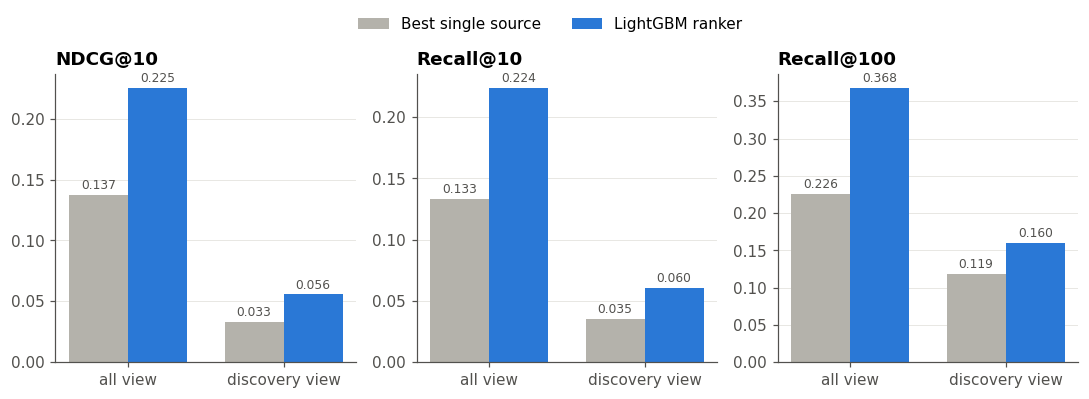

all view: LightGBM NDCG@10 0.225 versus 0.137 for the best single source (Two-tower), +64%; candidate recall ceiling 40.0%, ranker Recall@100 36.8%.
discovery view: LightGBM NDCG@10 0.056 versus 0.033 for the best single source (Two-tower), +70%; candidate recall ceiling 20.3%, ranker Recall@100 16.0%.


In [2]:
s1 = {v: load(RES / f'stage1_{v}.json') for v in VIEWS}
s2 = {v: load(RES / f'stage2_{v}.json') for v in VIEWS}
COLS = [f'{m}@{k}' for m in ('recall', 'ndcg', 'coverage') for k in (10, 50, 100)]
rows = []
for v in VIEWS:
    if not s2[v]: continue
    best = s2[v]['best_single_source']
    st1 = s1[v] or {}
    if st1:
        rows.append({'view': v, 'stage': 'Stage 1: union of candidates', 'candidate_recall@500': st1['candidate_recall@500']})
    bm = st1.get('sources', {}).get(best['source'], {'ndcg@10': best['ndcg@10']})
    rows.append({'view': v, 'stage': f"Stage 1: best single source ({NAME.get(best['source'], best['source'])})", **{c: bm.get(c) for c in COLS}})
    rows.append({'view': v, 'stage': 'Stage 2: LightGBM ranker', **{c: s2[v][c] for c in COLS}})
if not rows:
    print('Stage-2 results not available yet; section skipped.')
else:
    funnel = pd.DataFrame(rows).set_index(['view', 'stage']).reindex(columns=['candidate_recall@500'] + COLS).astype(float)
    display(fmt_table(funnel))
    MET = ['ndcg@10', 'recall@10', 'recall@100']
    views = [v for v in VIEWS if s2[v]]
    fig, axes = plt.subplots(1, len(MET), figsize=(12, 3.4))
    x, w = np.arange(len(views)), 0.38
    for ax, m in zip(axes, MET):
        for j, (lbl, pick, c) in enumerate([('Best single source', 'best', GREY), ('LightGBM ranker', 'LightGBM', BLUE)]):
            vals = [funnel.loc[v][funnel.loc[v].index.str.contains(pick)][m].iloc[0] for v in views]
            b = ax.bar(x + (j - 0.5) * w, vals, w, color=c, label=lbl)
            bar_labels(ax, b, vals)
        ax.set_xticks(x, [f'{v} view' for v in views]); ax.set_title(m.replace('recall', 'Recall').replace('ndcg', 'NDCG').replace('coverage', 'Coverage'))
    fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.07))
    save(fig, '15_ranker_vs_best_source')
    for v in views:
        best = s2[v]['best_single_source']
        msg = (f"{v} view: LightGBM NDCG@10 {s2[v]['ndcg@10']:.3f} versus {best['ndcg@10']:.3f} for the best single source "
               f"({NAME.get(best['source'], best['source'])}), {s2[v]['ndcg@10'] / best['ndcg@10'] - 1:+.0%}")
        if s1[v]:
            msg += f"; candidate recall ceiling {s1[v]['candidate_recall@500']:.1%}, ranker Recall@100 {s2[v]['recall@100']:.1%}"
        print(msg + '.'); notes.append(msg + '.')

## 2. Ranker training

Size of the training data (cutoff A candidates of users with at least one positive) and the early-stopping result on a 10% hold-out of those users.

In [3]:
STATS = ['train_users', 'train_rows', 'train_positives', 'val_users', 'best_iteration', 'val_ndcg@10', 'train_time_s']
if not any(s2.values()):
    print('Stage-2 results not available yet; section skipped.')
else:
    st = pd.DataFrame({v: {k: d.get(k) for k in STATS} for v, d in s2.items() if d})
    display(st.style.format(lambda x: f'{x:.3f}' if isinstance(x, float) and x < 1 else f'{x:,.0f}', na_rep='–'))
    msg = '; '.join(f"{v}: {st.loc['train_rows', v]:,.0f} rows, {st.loc['train_positives', v] / st.loc['train_rows', v]:.1%} positive, "
                    f"stopped at iteration {st.loc['best_iteration', v]:,.0f}" for v in st.columns)
    print(msg); notes.append('Ranker training ' + msg + '.')

,all,discovery
train_users,"3,837","1,868"
train_rows,"1,578,931","856,190"
train_positives,"46,683","7,523"
val_users,449,223
best_iteration,191,91
val_ndcg@10,0.362,0.317
train_time_s,15,5


all: 1,578,931 rows, 3.0% positive, stopped at iteration 191; discovery: 856,190 rows, 0.9% positive, stopped at iteration 91


## 3. Feature importance

Total split gain of the 15 most important features per view, as a share of the gain of the 25 features stored in the results file. Colours group features by origin.

all view: top feature `days_since_play` (21.1% of gain); feature groups by gain: user history with track 41%, retrieval source 24%, user 21%, track 12%, user-artist affinity 2%.
discovery view: top feature `i_trend` (10.6% of gain); feature groups by gain: track 37%, retrieval source 36%, user 16%, user-artist affinity 11%.


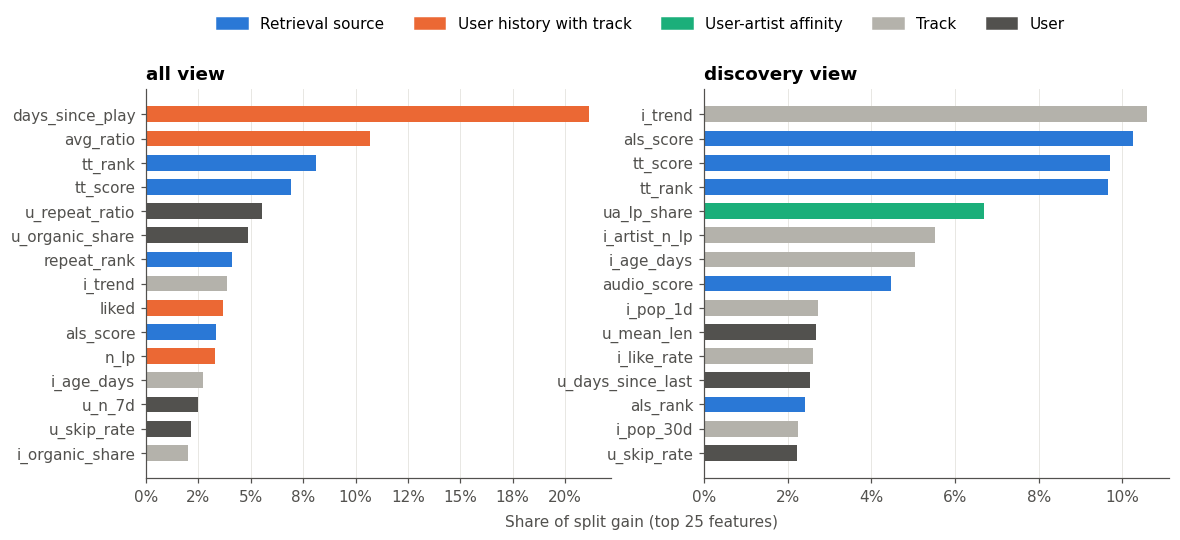

In [4]:
HIST = {'n_listen', 'n_lp', 'days_since_play', 'avg_ratio', 'liked', 'disliked'}
GROUP_COLOR = {'Retrieval source': BLUE, 'User history with track': ORANGE, 'User-artist affinity': AQUA, 'Track': GREY, 'User': INK}
def group(f):
    if f.endswith(('_rank', '_score')) or f == 'n_sources': return 'Retrieval source'
    if f in HIST: return 'User history with track'
    if f.startswith('ua_'): return 'User-artist affinity'
    if f.startswith('i_') or f == 'has_audio': return 'Track'
    return 'User'
views = [v for v in VIEWS if s2[v]]
if not views:
    print('Stage-2 results not available yet; section skipped.')
else:
    fig, axes = plt.subplots(1, len(views), figsize=(6 * len(views), 4.6), squeeze=False)
    for ax, v in zip(axes[0], views):
        g = pd.Series(s2[v]['feature_importance_gain'])
        g = (g / g.sum()).nlargest(15)
        ax.barh(g.index, g.values, color=[GROUP_COLOR[group(f)] for f in g.index], height=0.65)
        ax.invert_yaxis(); ax.grid(True, axis='x'); ax.grid(False, axis='y')
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_title(f'{v} view')
        full = pd.Series(s2[v]['feature_importance_gain']); share = full.groupby(full.index.map(group)).sum() / full.sum()
        msg = (f"{v} view: top feature `{g.index[0]}` ({g.iloc[0]:.1%} of gain); feature groups by gain: "
               + ', '.join(f'{k.lower()} {x:.0%}' for k, x in share.sort_values(ascending=False).items()) + '.')
        print(msg); notes.append(msg)
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOR.values()], labels=list(GROUP_COLOR),
               loc='upper center', ncol=len(GROUP_COLOR), bbox_to_anchor=(0.5, 1.05))
    fig.supxlabel('Share of split gain (top 25 features)', color=INK, fontsize=10)
    save(fig, '16_feature_importance')

## 4. Serving latency

In-process benchmark of the serving path (`yrec.serve --bench`): candidate retrieval from all sources, feature assembly and LightGBM scoring for a single user request, in milliseconds.

In [5]:
lat = load(RES / 'serving_latency.json')
if not lat:
    print('Serving benchmark not available yet; section skipped.')
else:
    lt = pd.DataFrame([{'view': v, 'stage': s, **p} for v in VIEWS if v in lat for s, p in lat[v].items()]).set_index(['view', 'stage'])
    display(lt.style.format('{:.1f} ms'))
    extra = {k: lat[k] for k in ('users', 'peak_rss_mb', 'faiss_threads') if k in lat}
    msg = '; '.join(f"{v} view p50 {lt.loc[(v, 'total'), 'p50']:.0f} ms / p95 {lt.loc[(v, 'total'), 'p95']:.0f} ms end to end, "
                    f"of which retrieval p50 {lt.loc[(v, 'retrieval'), 'p50']:.0f} ms" for v in VIEWS if (v, 'total') in lt.index)
    if extra:
        msg += f" ({', '.join(f'{k.replace(chr(95), chr(32))} {x:,}' for k, x in extra.items())})"
    print(msg + '.'); notes.append('Serving latency: ' + msg + '.')

all view p50 86 ms / p95 93 ms end to end, of which retrieval p50 77 ms; discovery view p50 87 ms / p95 93 ms end to end, of which retrieval p50 78 ms (users 200, peak rss mb 4,345, faiss threads 16).


## Summary

Bullet points below are computed from the result files in the cells above.

In [6]:
display(Markdown('\n'.join(f'- {n}' for n in notes) if notes else '- No result files were available when this notebook ran.'))

- all view: LightGBM NDCG@10 0.225 versus 0.137 for the best single source (Two-tower), +64%; candidate recall ceiling 40.0%, ranker Recall@100 36.8%.
- discovery view: LightGBM NDCG@10 0.056 versus 0.033 for the best single source (Two-tower), +70%; candidate recall ceiling 20.3%, ranker Recall@100 16.0%.
- Ranker training all: 1,578,931 rows, 3.0% positive, stopped at iteration 191; discovery: 856,190 rows, 0.9% positive, stopped at iteration 91.
- all view: top feature `days_since_play` (21.1% of gain); feature groups by gain: user history with track 41%, retrieval source 24%, user 21%, track 12%, user-artist affinity 2%.
- discovery view: top feature `i_trend` (10.6% of gain); feature groups by gain: track 37%, retrieval source 36%, user 16%, user-artist affinity 11%.
- Serving latency: all view p50 86 ms / p95 93 ms end to end, of which retrieval p50 77 ms; discovery view p50 87 ms / p95 93 ms end to end, of which retrieval p50 78 ms (users 200, peak rss mb 4,345, faiss threads 16).